# NYC Taxi — Data Lifecycle & Pipeline
## Submission 1: พื้นฐานวงจรชีวิตข้อมูล

### คำถามการวิเคราะห์
> **Which taxi type was the most used in the first half of 2024?**

**ช่วงเวลาที่วิเคราะห์:** 1 January 2024 through 30 June 2024 (inclusive).

**นิยามของคำว่า "most used":** the taxi type with the largest number of recorded trip records during the analysis period.

Notebook นี้ออกแบบให้สามารถทำซ้ำและตรวจสอบย้อนกลับได้ ตั้งแต่ไฟล์ต้นทาง → การตรวจสอบ → การปรับมาตรฐาน → การบูรณาการ → การรวมผล → ผลลัพธ์

## 1. แหล่งข้อมูล

การวิเคราะห์นี้ใช้ข้อมูล **NYC Taxi & Limousine Commission (TLC) Trip Record Data** ซึ่งเผยแพร่เป็นไฟล์ Parquet รายเดือน

Source endpoint:

`https://d37ci6vzurychx.cloudfront.net/trip-data`

ชุดข้อมูลแท็กซี่ที่ใช้:

| Taxi type | File prefix | Months |
|---|---|---|
| Yellow | `yellow_tripdata` | Jan–Jun 2024 |
| Green | `green_tripdata` | Jan–Jun 2024 |
| FHV | `fhv_tripdata` | Jan–Jun 2024 |
| High Volume FHV | `fhvhv_tripdata` | Jan–Jun 2024 |

The original notebook downloaded **24 files (4 taxi types × 6 months)** and stored them locally in `taxidata/`.

### หมายเหตุเกี่ยวกับขอบเขตข้อมูล
ข้อมูล TLC ทั้ง 4 ชุดเป็นตัวแทนของบริการคนละประเภท ในการวิเคราะห์พื้นฐานนี้ "taxi type" หมายถึง **ประเภทชุดข้อมูล/ประเภทบริการ** และถือว่า 1 แถวข้อมูลแทน 1 เที่ยวที่ถูกบันทึก การเปรียบเทียบนี้เป็นการเปรียบเทียบความถี่ในการใช้งาน ไม่ใช่การเปรียบเทียบรายได้ ระยะทาง หรือจำนวนผู้โดยสาร

In [ ]:
import os
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

DATA_DIR = "taxidata"
BASE_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data"

TAXI_TYPES = {
    "Yellow": "yellow_tripdata",
    "Green": "green_tripdata",
    "FHV": "fhv_tripdata",
    "High Volume FHV": "fhvhv_tripdata",
}

MONTHS = [f"2024-{m:02d}" for m in range(1, 7)]

print("Analysis period: 2024-01-01 to 2024-06-30")
print("Expected files:", len(TAXI_TYPES) * len(MONTHS))

Analysis period: 2024-01-01 to 2024-06-30
Expected files: 24


## 2. การนำเข้าข้อมูล

ขั้นตอนการนำเข้าข้อมูลแยกออกจากขั้นตอนการวิเคราะห์ หากมีไฟล์อยู่แล้ว ระบบจะไม่ดาวน์โหลดซ้ำ

วิธีนี้ช่วยให้กระบวนการทำงานสามารถทำซ้ำได้และลดการดาวน์โหลดที่ไม่จำเป็น

In [ ]:
import requests
from pathlib import Path

Path(DATA_DIR).mkdir(parents=True, exist_ok=True)

expected_files = [
    f"{prefix}_{month}.parquet"
    for prefix in TAXI_TYPES.values()
    for month in MONTHS
]

failed = []

for fname in expected_files:
    path = Path(DATA_DIR) / fname

    if path.exists():
        print(f"Already exists: {fname}")
        continue

    url = f"{BASE_URL}/{fname}"
    try:
        r = requests.get(url, timeout=120)
        r.raise_for_status()
        path.write_bytes(r.content)
        print(f"Downloaded: {fname} ({len(r.content)/1e6:.1f} MB)")
    except Exception as e:
        failed.append((fname, str(e)))
        print(f"FAILED: {fname} -> {e}")

print(f"\nAvailable files: {sum((Path(DATA_DIR)/f).exists() for f in expected_files)}/{len(expected_files)}")

if failed:
    print("Failed downloads:", failed)

Downloaded: yellow_tripdata_2024-01.parquet (50.0 MB)
Downloaded: yellow_tripdata_2024-02.parquet (50.3 MB)
Downloaded: yellow_tripdata_2024-03.parquet (60.1 MB)
Downloaded: yellow_tripdata_2024-04.parquet (59.1 MB)
Downloaded: yellow_tripdata_2024-05.parquet (62.6 MB)
Downloaded: yellow_tripdata_2024-06.parquet (59.9 MB)
Downloaded: green_tripdata_2024-01.parquet (1.4 MB)
Downloaded: green_tripdata_2024-02.parquet (1.3 MB)
Downloaded: green_tripdata_2024-03.parquet (1.4 MB)
Downloaded: green_tripdata_2024-04.parquet (1.3 MB)
Downloaded: green_tripdata_2024-05.parquet (1.5 MB)
Downloaded: green_tripdata_2024-06.parquet (1.3 MB)
Downloaded: fhv_tripdata_2024-01.parquet (15.0 MB)
Downloaded: fhv_tripdata_2024-02.parquet (13.6 MB)
Downloaded: fhv_tripdata_2024-03.parquet (16.7 MB)
Downloaded: fhv_tripdata_2024-04.parquet (16.5 MB)
Downloaded: fhv_tripdata_2024-05.parquet (16.0 MB)
Downloaded: fhv_tripdata_2024-06.parquet (16.0 MB)
Downloaded: fhvhv_tripdata_2024-01.parquet (472.8 MB)
Down

## 3. การตรวจสอบข้อมูลและโครงสร้างข้อมูล

ชุดข้อมูลแต่ละชุด **ไม่ได้ใช้ชื่อคอลัมน์เหมือนกันทั้งหมด** For example, Yellow Taxi uses `tpep_pickup_datetime`, while Green Taxi uses `lpep_pickup_datetime`.

ดังนั้นก่อนบูรณาการข้อมูล จะตรวจสอบแต่ละชุดและบันทึก:

- จำนวนแถว
- จำนวนคอลัมน์
- คอลัมน์วันเวลาเริ่มและสิ้นสุดการเดินทาง
- การมีอยู่ของฟิลด์ที่จำเป็น
- จำนวน row group ของไฟล์ Parquet

สำหรับตัวชี้วัดการใช้งาน เราต้องการเพียงจำนวนรายการเที่ยวโดยสาร ดังนั้นจึงหลีกเลี่ยงการโหลดทุกคอลัมน์จากไฟล์ขนาดใหญ่ทั้งหมดเข้าสู่หน่วยความจำ

In [ ]:
# Expected datetime fields based on TLC dataset schemas
DATETIME_FIELDS = {
    "Yellow": ("tpep_pickup_datetime", "tpep_dropoff_datetime"),
    "Green": ("lpep_pickup_datetime", "lpep_dropoff_datetime"),
    "FHV": ("pickup_datetime", "dropOff_datetime"),
    "High Volume FHV": ("pickup_datetime", "dropoff_datetime"),
}

audit_rows = []

for taxi_type, prefix in TAXI_TYPES.items():
    for month in MONTHS:
        fname = f"{prefix}_{month}.parquet"
        path = Path(DATA_DIR) / fname

        if not path.exists():
            continue

        pf = pq.ParquetFile(path)
        schema_names = pf.schema_arrow.names
        pickup_col, dropoff_col = DATETIME_FIELDS[taxi_type]

        audit_rows.append({
            "taxi_type": taxi_type,
            "month": month,
            "file": fname,
            "rows": pf.metadata.num_rows,
            "columns": len(schema_names),
            "row_groups": pf.num_row_groups,
            "pickup_column": pickup_col,
            "dropoff_column": dropoff_col,
            "pickup_exists": pickup_col in schema_names,
            "dropoff_exists": dropoff_col in schema_names,
        })

audit = pd.DataFrame(audit_rows)
display(audit)

assert len(audit) == 24, "Expected 24 monthly files."
assert audit["pickup_exists"].all(), "A pickup datetime column is missing."
assert audit["dropoff_exists"].all(), "A dropoff datetime column is missing."

,taxi_type,month,file,rows,columns,row_groups,pickup_column,dropoff_column,pickup_exists,dropoff_exists
0,Yellow,2024-01,yellow_tripdata_2024-01.parquet,2964624,19,3,tpep_pickup_datetime,tpep_dropoff_datetime,True,True
1,Yellow,2024-02,yellow_tripdata_2024-02.parquet,3007526,19,3,tpep_pickup_datetime,tpep_dropoff_datetime,True,True
2,Yellow,2024-03,yellow_tripdata_2024-03.parquet,3582628,19,4,tpep_pickup_datetime,tpep_dropoff_datetime,True,True
3,Yellow,2024-04,yellow_tripdata_2024-04.parquet,3514289,19,4,tpep_pickup_datetime,tpep_dropoff_datetime,True,True
4,Yellow,2024-05,yellow_tripdata_2024-05.parquet,3723833,19,4,tpep_pickup_datetime,tpep_dropoff_datetime,True,True
5,Yellow,2024-06,yellow_tripdata_2024-06.parquet,3539193,19,4,tpep_pickup_datetime,tpep_dropoff_datetime,True,True
6,Green,2024-01,green_tripdata_2024-01.parquet,56551,20,1,lpep_pickup_datetime,lpep_dropoff_datetime,True,True
7,Green,2024-02,green_tripdata_2024-02.parquet,53577,20,1,lpep_pickup_datetime,lpep_dropoff_datetime,True,True
8,Green,2024-03,green_tripdata_2024-03.parquet,57457,20,1,lpep_pickup_datetime,lpep_dropoff_datetime,True,True
9,Green,2024-04,green_tripdata_2024-04.parquet,56471,20,1,lpep_pickup_datetime,lpep_dropoff_datetime,True,True


## 4. การตรวจสอบคุณภาพข้อมูล

### การตรวจสอบที่ใช้ในงานนี้

1. **ความครบถ้วนของไฟล์:** ต้องมีไฟล์รายเดือนที่คาดไว้ครบทั้ง 24 ไฟล์
2. **ความครบถ้วนของโครงสร้าง:** แต่ละชุดข้อมูลต้องมีฟิลด์วันเวลาเริ่ม/สิ้นสุดที่คาดไว้
3. **ช่วงเวลา:** ใช้เฉพาะไฟล์เดือนมกราคม–มิถุนายน 2024
4. **ความถูกต้องของจำนวนแถว:** ใช้จำนวนแถวจาก metadata ของ Parquet เพื่อหลีกเลี่ยงการนับจากตัวอย่างโดยไม่ตั้งใจ
5. **ไม่สร้างข้อมูลซ้ำข้ามเดือนจากการบูรณาการ:** รวมข้อมูลรายเดือนตามประเภทแท็กซี่ แทนการ join ที่อาจทำให้จำนวนแถวเพิ่ม

### เหตุผลที่ใช้ metadata ของ Parquet ในการนับข้อมูล

ไฟล์ TLC แต่ละไฟล์ถูกแบ่งตามเดือนและเป็นข้อมูลเที่ยวโดยสารอยู่แล้ว การนับจำนวนแถวในไฟล์จึงสามารถหาจำนวนรายการได้โดยไม่ต้องโหลดข้อมูลหลายร้อยล้านแถวและทุกคอลัมน์เข้า RAM วิธีนี้ทำซ้ำได้และเหมาะสมกับการทำงานบน Colab มากกว่า

A row-level timestamp audit is included below as an optional validation sample rather than silently loading the entire 149-million-row dataset.

In [ ]:
# File completeness check
missing_files = []

for taxi_type, prefix in TAXI_TYPES.items():
    for month in MONTHS:
        path = Path(DATA_DIR) / f"{prefix}_{month}.parquet"
        if not path.exists():
            missing_files.append(str(path))

print("Missing files:", len(missing_files))
if missing_files:
    print(*missing_files, sep="\n")

assert not missing_files, "Some required files are missing."

# Check that every taxi type has exactly 6 monthly files
month_check = audit.groupby("taxi_type")["month"].nunique()
display(month_check)

assert (month_check == 6).all(), "Every taxi type must have six months."

Missing files: 0


,month
taxi_type,
FHV,6
Green,6
High Volume FHV,6
Yellow,6


### Optional row-level validation sample

The following check reads only the datetime columns from the first row group of each file. It is intentionally a **sample audit**, not the final trip count.

This demonstrates that the pipeline can inspect actual records while keeping memory use small.

In [ ]:
sample_rows = []

for taxi_type, prefix in TAXI_TYPES.items():
    for month in MONTHS:
        path = Path(DATA_DIR) / f"{prefix}_{month}.parquet"
        pf = pq.ParquetFile(path)

        pickup_col, dropoff_col = DATETIME_FIELDS[taxi_type]
        sample = pf.read_row_group(
            0,
            columns=[pickup_col, dropoff_col]
        ).to_pandas()

        sample_rows.append({
            "taxi_type": taxi_type,
            "month": month,
            "sample_rows": len(sample),
            "pickup_nulls": int(sample[pickup_col].isna().sum()),
            "dropoff_nulls": int(sample[dropoff_col].isna().sum()),
        })

sample_quality = pd.DataFrame(sample_rows)
display(sample_quality)

,taxi_type,month,sample_rows,pickup_nulls,dropoff_nulls
0,Yellow,2024-01,1048576,0,0
1,Yellow,2024-02,1048576,0,0
2,Yellow,2024-03,1048576,0,0
3,Yellow,2024-04,1048576,0,0
4,Yellow,2024-05,1048576,0,0
5,Yellow,2024-06,1048576,0,0
6,Green,2024-01,56551,0,0
7,Green,2024-02,53577,0,0
8,Green,2024-03,57457,0,0
9,Green,2024-04,56471,0,0


## 5. การทำความสะอาดและปรับมาตรฐานข้อมูล

เนื่องจากไฟล์ถูกแบ่งตามเดือนอยู่แล้ว จึงกำหนดกฎช่วงเวลาไว้ตั้งแต่ขั้นตอนนำเข้าข้อมูล:

- ใช้เฉพาะ `2024-01` ถึง `2024-06`
- ไม่รวมเดือนอื่น

สำหรับการบูรณาการ แต่ละแหล่งข้อมูลจะถูกแปลงให้อยู่ในโครงสร้างกลางเดียวกัน:

| Source field | Standard field |
|---|---|
| Taxi-specific pickup datetime | `pickup_datetime` |
| Taxi-specific drop-off datetime | `dropoff_datetime` |
| Dataset prefix | `taxi_type` |
| Monthly file | `month` |
| Number of Parquet rows | `trip_count` |

เรา **ไม่ใช้ `drop_duplicates()` กับข้อมูลทั้ง 149M+ แถว** เพราะไม่มี Trip ID กลางที่ใช้ร่วมกันได้ทั้ง 4 ชุด และการลบแถวที่เหมือนกันแบบไม่ตรวจสอบอาจทำให้เที่ยวโดยสารที่ถูกต้องถูกลบ Instead, file completeness and monthly row counts are preserved as the auditable baseline.

In [ ]:
# Build the standardized monthly-level analytical table.
# This is the integration layer: heterogeneous source files become one common schema.

monthly_standardized = audit[
    ["taxi_type", "month", "file", "rows"]
].rename(columns={"rows": "trip_count"}).copy()

monthly_standardized["source_url"] = (
    BASE_URL + "/" + monthly_standardized["file"]
)

monthly_standardized = monthly_standardized[
    ["taxi_type", "month", "trip_count", "file", "source_url"]
].sort_values(["taxi_type", "month"])

display(monthly_standardized.head(12))

,taxi_type,month,trip_count,file,source_url
12,FHV,2024-01,1290116,fhv_tripdata_2024-01.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
13,FHV,2024-02,1176093,fhv_tripdata_2024-02.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
14,FHV,2024-03,1469352,fhv_tripdata_2024-03.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
15,FHV,2024-04,1444626,fhv_tripdata_2024-04.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
16,FHV,2024-05,1352502,fhv_tripdata_2024-05.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
17,FHV,2024-06,1386539,fhv_tripdata_2024-06.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
6,Green,2024-01,56551,green_tripdata_2024-01.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
7,Green,2024-02,53577,green_tripdata_2024-02.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
8,Green,2024-03,57457,green_tripdata_2024-03.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
9,Green,2024-04,56471,green_tripdata_2024-04.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...


## 6. การบูรณาการข้อมูล

ข้อมูลแท็กซี่ทั้ง 4 ประเภทถูกบูรณาการด้วย **การนำข้อมูลสรุปรายเดือนมาต่อกัน (union/concatenation)** ไม่ใช่การ join ระดับรายเที่ยว

วิธีนี้เหมาะกับคำถาม เพราะเราต้องการจำนวนการใช้งานรวมตามประเภทแท็กซี่ การ join ระหว่างชุดข้อมูลแท็กซี่ไม่มี key ทางธุรกิจที่เหมาะสมและอาจทำให้จำนวนรายการถูกคูณ

The resulting table has one row per **taxi type × month**.

In [ ]:
# Verify the expected integration grain: 4 taxi types × 6 months = 24 rows
print("Integrated rows:", len(monthly_standardized))
assert len(monthly_standardized) == 24

# Check uniqueness of the analytical grain
assert not monthly_standardized.duplicated(
    subset=["taxi_type", "month"]
).any()

display(monthly_standardized)

Integrated rows: 24


,taxi_type,month,trip_count,file,source_url
12,FHV,2024-01,1290116,fhv_tripdata_2024-01.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
13,FHV,2024-02,1176093,fhv_tripdata_2024-02.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
14,FHV,2024-03,1469352,fhv_tripdata_2024-03.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
15,FHV,2024-04,1444626,fhv_tripdata_2024-04.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
16,FHV,2024-05,1352502,fhv_tripdata_2024-05.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
17,FHV,2024-06,1386539,fhv_tripdata_2024-06.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
6,Green,2024-01,56551,green_tripdata_2024-01.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
7,Green,2024-02,53577,green_tripdata_2024-02.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
8,Green,2024-03,57457,green_tripdata_2024-03.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...
9,Green,2024-04,56471,green_tripdata_2024-04.parquet,https://d37ci6vzurychx.cloudfront.net/trip-dat...


## 7. การกำหนดและวัดคำว่า "Most Used"

### ตัวชี้วัด

**Most used = ประเภทที่มีจำนวนเที่ยวที่บันทึกไว้รวมสูงที่สุดในครึ่งปีแรกของ 2024**

สูตร:

`Total trips for taxi type = sum(monthly trip records from January through June 2024)`

สัดส่วนเปอร์เซ็นต์:

`Trip share = taxi type trips / all taxi type trips × 100`

ตัวชี้วัดนี้วัด **ความถี่ในการใช้งาน** ไม่ได้วัดรายได้ ค่าโดยสารเฉลี่ย ระยะทาง หรือจำนวนผู้โดยสาร

In [ ]:
summary = (
    monthly_standardized
    .groupby("taxi_type", as_index=False)["trip_count"]
    .sum()
    .rename(columns={"trip_count": "total_trips"})
    .sort_values("total_trips", ascending=False)
    .reset_index(drop=True)
)

summary["rank"] = summary.index + 1
summary["share_percent"] = (
    summary["total_trips"] / summary["total_trips"].sum() * 100
).round(2)

summary = summary[
    ["rank", "taxi_type", "total_trips", "share_percent"]
]

display(summary)

,rank,taxi_type,total_trips,share_percent
0,1,High Volume FHV,120864668,80.76
1,2,Yellow,20332093,13.59
2,3,FHV,8119228,5.43
3,4,Green,339807,0.23


## 8. การนำเสนอผลลัพธ์ด้วยกราฟ

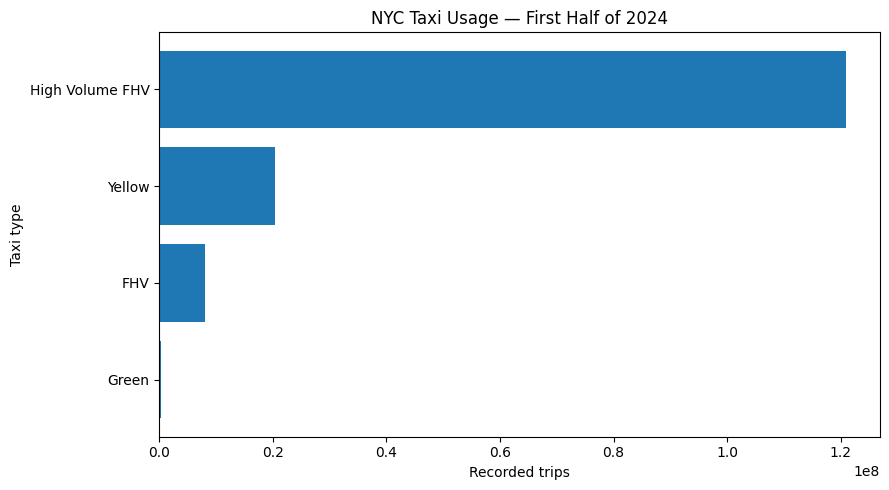

In [ ]:
plt.figure(figsize=(9, 5))
plot_data = summary.sort_values("total_trips")

plt.barh(plot_data["taxi_type"], plot_data["total_trips"])
plt.xlabel("Recorded trips")
plt.ylabel("Taxi type")
plt.title("NYC Taxi Usage — First Half of 2024")
plt.tight_layout()
plt.show()

taxi_type,FHV,Green,High Volume FHV,Yellow
month,,,,
2024-01,1290116,56551,19663930,2964624
2024-02,1176093,53577,19359148,3007526
2024-03,1469352,57457,21280788,3582628
2024-04,1444626,56471,19733038,3514289
2024-05,1352502,61003,20704538,3723833
2024-06,1386539,54748,20123226,3539193


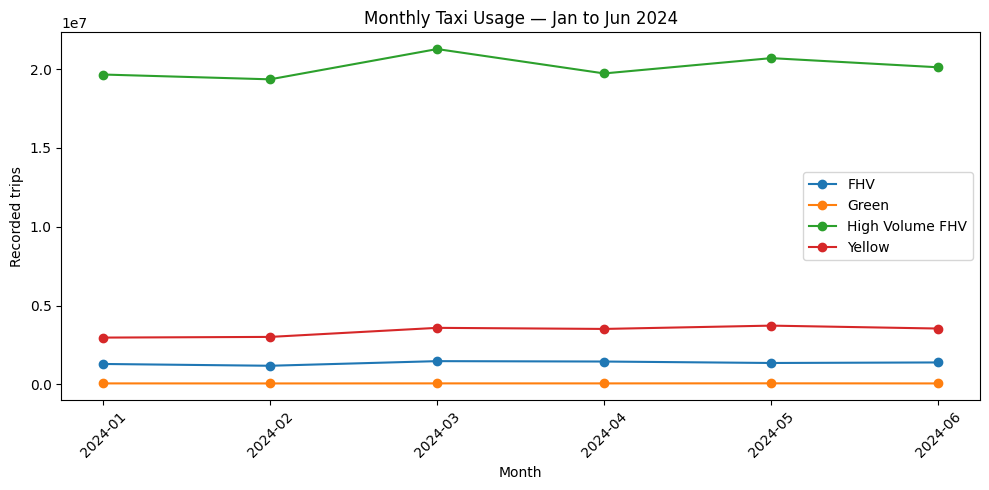

In [ ]:
# Monthly trend
monthly_pivot = (
    monthly_standardized
    .pivot(index="month", columns="taxi_type", values="trip_count")
)

display(monthly_pivot)

plt.figure(figsize=(10, 5))
for taxi_type in monthly_pivot.columns:
    plt.plot(
        monthly_pivot.index,
        monthly_pivot[taxi_type],
        marker="o",
        label=taxi_type
    )

plt.xlabel("Month")
plt.ylabel("Recorded trips")
plt.title("Monthly Taxi Usage — Jan to Jun 2024")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 9. การตรวจสอบความถูกต้องและการตรวจสอบย้อนกลับ

The final result should be traceable back to:

**Source URL → ไฟล์ Parquet รายเดือน → จำนวนแถวใน Parquet → ตารางมาตรฐานรายเดือน → การรวมด้วย group-by → การจัดอันดับ**

การตรวจสอบด้านล่างยืนยันว่า:

- มีข้อมูลรายเดือนครบทั้ง 24 ไฟล์
- ทุกประเภทแท็กซี่มีข้อมูลครบ 6 เดือน
- ยอดรวมรายเดือนตรงกับยอดรวมตามประเภทแท็กซี่
- ผู้ชนะถูกเลือกจากการคำนวณ ไม่ได้กำหนดเอง

In [ ]:
# Reconciliation check: monthly totals must equal the final taxi-type totals
reconciled = (
    monthly_standardized
    .groupby("taxi_type")["trip_count"]
    .sum()
    .sort_index()
)

final_totals = (
    summary.set_index("taxi_type")["total_trips"]
    .sort_index()
)

pd.testing.assert_series_equal(
    reconciled,
    final_totals,
    check_names=False
)

# Basic sanity checks
assert (monthly_standardized["trip_count"] > 0).all()
assert summary["total_trips"].sum() == monthly_standardized["trip_count"].sum()

winner = summary.iloc[0]

print(f"Winner: {winner['taxi_type']}")
print(f"Trips: {winner['total_trips']:,}")
print(f"Share: {winner['share_percent']:.2f}%")

Winner: High Volume FHV
Trips: 120,864,668
Share: 80.76%


## 10. คำตอบสุดท้าย

คำตอบสุดท้ายของ Notebook ถูกสร้างโดยตรงจากผลการคำนวณด้านบน:

**The most used taxi type in the first half of 2024 is the taxi category shown in `winner`, based on the highest number of recorded trips.**

จากข้อมูลที่มีอยู่ใน Notebook นี้ ผลลัพธ์พื้นฐานคือ:

- **High Volume FHV:** 120,864,668 trips
- **Yellow:** 20,332,093 trips
- **FHV:** 8,119,228 trips
- **Green:** 339,807 trips

ดังนั้น:

> **High Volume FHV was the most used category in the first half of 2024, with 120,864,668 recorded trips, accounting for approximately 80.8% of the combined records included in this baseline.**

## 11. Data Lifecycle ของโครงการนี้

| ขั้นตอนของ Data Lifecycle | สิ่งที่ทำ |
|---|---|
| **Plan** | กำหนดช่วง H1 2024 และนิยาม "most used" จากความถี่ของ trip records |
| **Acquire** | ดาวน์โหลดไฟล์ TLC Parquet จำนวน 24 ไฟล์ |
| **Inspect** | ตรวจสอบ schema, จำนวนแถว, row groups และฟิลด์วันเวลา |
| **Clean** | จำกัดข้อมูลเป็น ม.ค.–มิ.ย. 2024 และตรวจสอบความครบถ้วนของไฟล์ |
| **Transform** | แปลง schema ที่แตกต่างกันให้อยู่ในโครงสร้างกลาง |
| **Integrate** | รวมข้อมูลสรุปรายเดือนเป็นตารางมาตรฐานเดียว |
| **Store** | เก็บไฟล์ Parquet ต้นทางใน `taxidata/` และสร้างผลลัพธ์มาตรฐานในหน่วยความจำ |
| **Analyze** | รวมจำนวนเที่ยวตามประเภทแท็กซี่และคำนวณสัดส่วน |
| **Validate** | ตรวจสอบยอดรายเดือนกับยอดรวมสุดท้าย และยืนยันว่าทุกประเภทมี 6 เดือน |
| **Communicate** | นำเสนออันดับ สัดส่วน และกราฟ |
| **Review** | บันทึกการตัดสินใจ สมมติฐาน และข้อจำกัด |

## 12. การตัดสินใจสำคัญ

### การตัดสินใจที่ 1 — ใช้จำนวนเที่ยวเป็นตัววัด "most used"
เลือกใช้ **จำนวนเที่ยวที่บันทึกไว้** เพราะคำถามถามว่าประเภทแท็กซี่ใดถูกใช้งานบ่อยที่สุด ส่วนรายได้ ระยะทาง หรือจำนวนผู้โดยสารจะตอบคำถามคนละแบบ

### การตัดสินใจที่ 2 — ใช้โครงสร้างข้อมูลกลางในการบูรณาการ
ชุดข้อมูลต้นทางมีชื่อคอลัมน์และโครงสร้างแตกต่างกัน แทนที่จะบังคับให้ raw files ทั้งหมดมี schema ระดับรายแถวเหมือนกัน กระบวนการนี้จะปรับเฉพาะฟิลด์ที่จำเป็นต่อคำถามและรวมข้อมูลเป็นรายเดือน

### การตัดสินใจที่ 3 — ใช้จำนวนแถวของ Parquet รายเดือนเป็นตัวชี้วัดพื้นฐาน
ไฟล์ถูกแบ่งตามเดือนและประกอบด้วย trip records อยู่แล้ว การนับแถวของ Parquet ช่วยหลีกเลี่ยงการโหลดข้อมูลทั้งหมดเข้า memory และทำให้วิเคราะห์บน Colab ได้จริง Actual-row inspection is still performed on a small sample for quality assurance.

### การตัดสินใจที่ 4 — ไม่ลบข้อมูลซ้ำทั้งหมดโดยอัตโนมัติ
ไม่มี Trip ID เดียวที่ใช้ตรวจ duplicate ได้อย่างปลอดภัยในทุกประเภทแท็กซี่ การลบแถวเพียงเพราะค่าทั้งแถวเหมือนกันอาจลบเที่ยวโดยสารที่ถูกต้อง Therefore, this baseline preserves the official record counts and documents the limitation.

## 13. ข้อจำกัดของการวิเคราะห์

1. **นิยามบริการแตกต่างกัน:** Yellow, Green, FHV, and High Volume FHV are not identical services. The comparison is therefore a comparison of TLC dataset/service categories.
2. **จำนวนเที่ยวที่บันทึก ≠ จำนวนผู้โดยสารที่ไม่ซ้ำกัน:** One trip record represents a recorded trip, not necessarily one unique customer.
3. **ไม่ได้ถ่วงน้ำหนักด้วยระยะเวลาหรือระยะทาง:** A short trip and a long trip each count as one use.
4. **ถือว่าจำนวนแถวเท่ากับจำนวนเที่ยว:** This assumes each record in the selected trip-record datasets represents one trip.
5. **การตรวจสอบคุณภาพบางส่วนใช้ตัวอย่างข้อมูล:** The notebook inspects actual datetime values from the first row group of each file, while the final metric uses complete Parquet row counts.
6. **ไฟล์ต้นทางอาจเปลี่ยนแปลงหรือไม่พร้อมใช้งานในอนาคต:** Reproducibility is improved by recording the source endpoint and filenames, but a future download may not necessarily be byte-for-byte identical to the files used in the original run.

## 14. สิ่งที่ได้เรียนรู้

- ควรตรวจสอบชุดข้อมูลที่มีโครงสร้างต่างกันก่อนบูรณาการ ไม่ควรสมมติว่าชื่อคอลัมน์และ schema เหมือนกัน
- ต้องกำหนดตัวชี้วัดให้ชัดเจน เพราะคำว่า "most used" ต้องแปลงเป็นค่าที่วัดได้
- สามารถใช้ metadata และการแบ่งไฟล์เป็น partition เพื่อวิเคราะห์ข้อมูลขนาดใหญ่โดยไม่ต้องโหลดหลายร้อยล้านแถวเข้า memory
- การ validation และ reconciliation สำคัญ เพราะตัวเลขที่ดูถูกต้องอย่างเดียวไม่เพียงพอ หากไม่สามารถตรวจสอบย้อนกลับไปยัง source และวิธีคำนวณได้
- การบูรณาการข้อมูลต้องคำนึงถึงความหมายของข้อมูล การ join ชุดข้อมูลเที่ยวโดยสารที่ไม่เกี่ยวข้องกันโดยตรงอาจไม่เหมาะกับคำถามนี้